In [89]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/27/2022
# version ='1.0'

# Demo: Further Experiments on Solving a Small SDP by Barrier Method -- III (continue.)

In the previous experiments, the barrier method was used to solve the following SDP problem, in which the problem parameters, $c, F, G$ were constructed in a way that the SDP problem was feasible.

\begin{equation}
\begin{array}{rl}
\text{minimize} & c^Tx \\
\text{subject to} & F(x)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G \preceq 0 \\
\end{array}
\end{equation}
where $x\in R^n$, and $F_i\in S^p, G\in S^p$. 

In this demo, further experiments are simulated in which SDP problem is infeasible by choosing special $F, G$ .

Here are the explanations on how to create an infeasible SDP problem. 

The inequality system for the SDP problem is
\begin{equation}
\label{eq:NL49-primal}
\begin{array}{rl}
\text{minimize} & 0 \\
\text{subject to} & F(x) \preceq 0 \\
\end{array}
\end{equation}

The dual function of the above inequality system is
\begin{equation}
\begin{array}{rcl}
g(Z) & = & \displaystyle{\inf_{x\in \mathbf{R}^n}\left(\sum_{i}x_i tr(ZF_i)+tr(ZG)\right)} \\
 & = & \left\{\begin{array}{rl}
 -\infty & \text{if any } tr(ZF_i)\neq 0 \\
 tr(ZG) & \text{if all } tr(ZF_i)=0 \\
\end{array}  \right.
\end{array}
\end{equation}

Note that $g(Z)$ is homogeneous,i.e., if $\exists Z\succeq 0$, $g(Z)>0$, then $g(\beta Z)=\beta g(Z)\rightarrow 0$ if $\beta\rightarrow +\infty$. 

According to the theorem of the alternative, if one can find $Z$ to satisfy the following inequality system, the problem will be infeasible.
\begin{equation}
\begin{array}{ccc}
tr(ZF_i)=0, i=1,2,...,n; &  tr(ZG)>0; &  Z\succeq 0 \\
\end{array}
\end{equation}

The algorithm to construct an infeasible problem with parameters $F_i,i=1,2,...,n$ and $G$ is listed in the following algorithm,

### Procedure to generate $F, G$ for an infeasible SDP problem
1. Randomly to generate $Z\in S^p_{++}$
1. Generate $F_i\in S^p$ satisfying $tr(ZF_i)=0$, for $i=1,2,...,n$
1. Repeating generating $G\in S^p$ until it is satisfying $tr(ZG)>0$


Interested readers can refer to prior demo on how to construct $F, G$ for a feasible SDP problem.

After $F, G$ are constructed, they are applied to the standard phase I feasibility problem in the following problem,

\begin{equation}
\begin{array}{rl}
\text{minimize} & s \\
\text{subject to} & R(x,s)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G-sI \preceq 0 \\
\end{array}
\end{equation}

which is also a SDP problem, with
$$
\begin{array}{rcl}
\hat{c} & = & \left[\begin{array}{c}
\mathbf{0}_{n} \\
1 \\
\end{array} \right] \\
\hat{n} & = n+1 \\
\hat{F} & = & R(x,s) \\
\hat{F}_i & = & F_i,i=1,2,...,n \\
\hat{F}_{\hat{n}} & = & -\mathbf{I}_{p\times p} \\
\hat{G} & = G \\
\end{array}
$$

Its dual problem (refer to example 11.9 in the textbook) is
$$
\begin{array}{rcl}
\text{maximize} & tr(\hat{G}\hat{Z}) & \\
\text{subject to} & tr(\hat{F}_i\hat{Z})+\hat{c}_i = 0 & i=1,2,...,\hat{n} \\
& \hat{Z} \succeq 0 \\
\end{array}
$$

Hence, the matrix $\hat{Z}^*(t)=\dfrac{1}{t}(-F(x^*(t)))^{-1}$ is strictly feasible for dual problem, i.e., a lower bound of $s$ in the phase I feasibility problem is $tr(\hat{G}\hat{Z}^*(t))$. During the centering step if $tr(\hat{G}\hat{Z}^*(t))>0$, then the SDP problem is infeasible, so barrier method can be stopped early before reaching to convergence.

In [90]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from matplotlib.ticker import MultipleLocator

In [91]:
def is_pos_def(x):
    """
    utility function, check whether matrix x is positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) > 0)


def is_neg_def(x):
    """
    utility function, check whether matrix x is negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) < 0)


def is_semi_pos_def(x):
    """
    utility function, check whether matrix x is semi-positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) >= 0)


def is_semi_neg_def(x):
    """
    utility function, check whether matrix x is semi-negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) <= 0)

$f_0(x)=c^Tx$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0$

In [92]:
def my_f_0(x, c, F, G):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, c, F, G):
    return True


def my_gradient_f_0(x, c, F, G):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return c


def my_hessian_f_0(x, c, F, G):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-\log det(-F(x))$

If overflow occurs in calculating $det(-F(x))$,
then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
until no overflow occurs.

It requires $F(x)\succ 0$.

The gradient of $\phi(x)$,
   
   \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}

The Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$

In [93]:
def my_phi(x, c, F, G):
    """
    $\phi(x)=-\log det(-F(x))$
    If overflow occurs in calculating $det(-F(x))$,
    then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
    until no overflow occurs.
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        phi = -1 * np.log(np.linalg.det(-Fx))
        if phi < 0 and np.isinf(phi):
            scale = 0.5
            while scale >= 2 ** -30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 1 / 2
            if np.isinf(phi):
                raise RuntimeError('phi = -inf')
            return phi
        elif phi > 0 and np.isinf(phi):
            scale = 2
            while scale <= 2 ** 30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 2
            if np.isinf(phi):
                raise RuntimeError('phi = +inf')
            return phi
        else:
            return phi


def my_phi_feasible(x, c, F, G):
    """
    It requires $F(x)\succ 0 $
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    return is_semi_neg_def(Fx)


def my_gradient_phi(x, c, F, G):
    """
    gradient of $\phi(x)$
    \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    g = [np.trace(-1 * np.linalg.inv(Fx) @ F[i]) for i in range(n)]
    return np.reshape(np.array(g), (n, 1))


def my_hessian_phi(x, c, F, G):
    """
    Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]

    minus_inv_Fx = -1 * np.linalg.inv(Fx)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            H[i][j] = np.trace(minus_inv_Fx @ F[j] @ minus_inv_Fx @ F[i])

    if not is_pos_def(H):
        raise RuntimeError('Hessian should be positive.')
    return H

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [94]:
def my_f(x, t, c, F, G):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_f_0(x, c, F, G) + my_phi(x, c, F, G)


def my_f_feasible(x, t, c, F, G):
    return my_f_0_feasible(x, c, F, G) and my_phi_feasible(x, c, F, G)


def my_gradient_f(x, t, c, F, G):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_gradient_f_0(x, c, F, G) + my_gradient_phi(x, c, F, G)


def my_hessian_f(x, t, c, F, G):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_hessian_f_0(x, c, F, G) + my_hessian_phi(x, c, F, G)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$



In [95]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [96]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

early exist condition

In [97]:
def exit_condition_f(x0):
    """
    early exist condition
    :param x0:
    :return:
    """
    s = x0[-1]
    early_exit = False
    if s < 0:
        early_exit = True
    return early_exit

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

The centering step will stop early if the exist condition is satisfied.

In [98]:
def centering_step_with_early_exit_condition(x0, epsilon, alpha, beta, barrier_t, c, F, G, early_exit_condition_f):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    The centering step will stop early if the exist condition is satisfied.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param c:
    :param F:
    :param G:
    :param early_exit_condition_f:
    :return:
    """
    x = x0
    args = (barrier_t, c, F, G)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_search_steps = []
    fx = [my_f(x, *args)]
    decrements = [decrement]
    iteration = 1
    while decrement / 2 > epsilon:
        step = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        x_next = x + step * x_nt
        x = x_next

        if early_exit_condition_f(x):
            #print('Info: Early exit condition satisfied.')
            break

        x_nt, decrement = my_newton_step_decrement(x, args)

        #print(r'Info: iteration={}, barrier_t={}, decrement={}, line search step ={}, step.s={}, s={}, f={}'.format(iteration, barrier_t,
        #                                                                                     decrement, step, x_nt[-1], x[-1], my_f(x, *args)))
        line_search_steps.append(step)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_search_steps

Solve the standard phase-I feasibility SDP problem and if feasible, return the strictly feasible point

Refer to FlexibleLecture Note for details

In [99]:
def solve_phase_I_feasibility_SDP(F, G, mu):
    """
    Solve the standard phase-I feasibility SDP problem and if feasible, return the strictly feasible point
    Refer to FlexibleLecture Note for details
    :param F:
    :param G:
    :param mu:
    :return:
    """
    n_hat, p, _ = F.shape
    c_hat = np.zeros((n_hat + 1, 1))
    c_hat[n_hat][0] = 1
    F_hat = np.zeros((n_hat + 1, p, p))
    np.copyto(F_hat[0:n_hat], F)
    F_hat[n_hat] = -np.eye(p)
    G_hat = G.copy()

    x0 = np.random.normal(loc=0, scale=1, size=(n_hat, 1))
    Tmp = G_hat.copy()
    for i in range(n_hat):
        Tmp += x0[i] * F_hat[i]
    eig_vals = np.linalg.eigvals(Tmp)
    s = np.max(eig_vals) + 1

    xs0 = np.block([[x0], [np.reshape(np.array([s]), (1, 1))]])

    Tmp = G_hat.copy()
    for i in range(n_hat + 1):
        Tmp += xs0[i] * F_hat[i]
    if not is_neg_def(Tmp):
        raise RuntimeError('xs0 should be negative definite.')

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-4

    t0 = 1
    t = t0

    # To ensure that the initial point is on the central path with t_0 = 1
    args = (t, c_hat, F_hat, G_hat)
    xst, n_iter, _, _, _ = centering_step_with_early_exit_condition(xs0, epsilon, alpha, beta, *args, exit_condition_f)
    xs0 = xst
    t = mu * t
    cumulative_iter = n_iter
    n_hat = len(xst)

    feasible = False
    while True:
        args = (t, c_hat, F_hat, G_hat)

        xst, n_iter, _, _, _ = centering_step_with_early_exit_condition(xs0, epsilon, alpha, beta, *args, exit_condition_f)
        xs0 = xst
        cumulative_iter = cumulative_iter + n_iter

        f0 = my_f_0(xs0, c_hat, F_hat, G_hat)
        if f0 < 0:
            #print('Info: feasibility detected due to s = {}'.format(my_f_0(xs0, c_hat, F_hat, G_hat)))
            feasible = True
            break

        F_asterisk_t = G_hat.copy()
        for i in range(len(xs0)):
            F_asterisk_t += xs0[i] * F_hat[i]
        Z_asterisk_t = np.linalg.inv(-F_asterisk_t) / t
        dual = np.trace(G_hat @ Z_asterisk_t)
        if dual > 0:
            #print('Info: infeasibility detected due to dual = {}'.format(dual))
            feasible = False
            break

        if p / t < duality_gap_epsilon:
            break
        else:
            t = mu * t

    if feasible == True:
        return xs0[0:n_hat-1], cumulative_iter
    else:
        return None, cumulative_iter

Procedure to generate parameters $(c, F, G, x^*, Z^*, p^*=1)$ and initial starting point $x_0$

Refer to FlexibleLecture Note for details

In [100]:
def get_feasible_c_F_G_xp_Z(n, p, p_asterisk):
    """
    Procedure to generate parameters $(c, F, G, x^*, Z^*, p^*=1)$ and initial starting point $x_0$
    Refer to FlexibleLecture Note for details
    :param n:
    :param p:
    :param p_asterisk:
    :return:
    """
    if not p_asterisk > 0:
        raise RuntimeError('Only fp > 0 is supported yet.')

    count = 0
    while True:
        x_asterisk = np.random.uniform(low=-1.0, high=1.0, size=(n, 1))
        dx = np.random.uniform(low=-1.0, high=1.0, size=(n, 1))
        assert (not np.allclose(dx[n - 1][0], 0))
        F = np.zeros((n, p, p))
        A = np.random.rand(p, p)
        S = -1 * (A @ A.T)  # -S is SDP

        for i in range(n - 1):
            Tmp = np.random.normal(loc=0, scale=1.0, size=(p, p))
            F[i] = (Tmp + Tmp.T) / 2

        Tmp = np.zeros((p, p))
        for i in range(n - 1):
            Tmp += dx[i][0] * F[i]

        F[n - 1] = (S - Tmp) / dx[n - 1][0]

        Tmp = np.zeros((p, p))
        for i in range(n):
            Tmp += dx[i][0] * F[i]

        if not is_neg_def(Tmp):
            raise RuntimeError('F(dx)-G should be negative definite!')

        G = np.zeros((p, p))
        for i in range(n):
            G += -x_asterisk[i][0] * F[i]

        B = np.random.rand(p, p)
        Z_tmp = B @ B.T
        scale = p_asterisk / np.trace(Z_tmp @ G)
        if scale > 0:
            Z = Z_tmp * scale
            # print('Info: Z is constructed.')
            break
        else:
            count += 1
            #print('Info: The {}-th dial to generate Z failed, continue the next dial'.format(count))
            continue

    if not np.allclose(np.trace(Z @ G), p_asterisk):
        raise RuntimeError('it is requiring the optimal value is fp.')

    Tmp = G.copy()
    for i in range(n):
        Tmp += x_asterisk[i][0] * F[i]

    if not np.allclose(Tmp, np.zeros((p, p))):
        raise RuntimeError('it should satisfy the optimal condition, F(xp)=0')

    x0 = x_asterisk + dx

    Tmp = G.copy()
    for i in range(n):
        Tmp += x0[i][0] * F[i]

    if not is_neg_def(Tmp):
        raise RuntimeError('it should have F(x0)<0')

    c = np.zeros((n, 1))
    for i in range(n):
        c[i][0] = -np.trace(Z @ F[i])

    return c, F, G, Z, x_asterisk, x0

Procedure to generate model parameters $F, G$ that the SDP is infeasible

Refer to FlexibleLecture Note for the detail

In [101]:
def get_infeasible_F_G(n, p):
    """
    Procedure to generate model parameters $F, G$ that the SDP is infeasible
    Refer to FlexibleLecture Note for the detail
    :param n:
    :param p:
    :return:
    """
    Tmp = np.random.rand(p, p)
    Z = Tmp @ Tmp.T
    m = int(p * (p+1) / 2)
    z = np.zeros((m, 1))
    offset = 0
    for i in range(p):
        if i == 0:
            z[offset: offset+(p-i)]= 0.5 * np.reshape(np.diag(Z, k=i), (-1, 1))
        else:
            z[offset: offset + (p - i)] = np.reshape(np.diag(Z, k=i), (-1, 1))
        offset += (p-i)

    ns = null_space(z.T)
    F = np.zeros((n, p, p))
    for i in range(n):
        y = ns[:, i]
        offset = 0
        for j in range(p):
            F[i][np.where(np.eye(p, k=j) == 1)] = np.squeeze(y[offset: offset+(p-j)])
            if j > 0:
                F[i][np.where(np.eye(p, k=-j) == 1)] = np.squeeze(y[offset: offset + (p - j)])
            offset += (p - j)

    n_dial = 0
    G = np.zeros((p, p))
    threshold = 0.1
    while True:
        n_dial = n_dial + 1
        if n_dial > 100:
            raise RuntimeError('Info: after 100 dials, it is still unable to construct the model parameters.')

        y = np.random.normal(loc=0, scale=1, size=(m, 1))
        offset = 0
        for j in range(p):
            G[np.where(np.eye(p, k=j) == 1)] = np.squeeze(y[offset: offset+(p-j)])
            if j > 0:
                G[np.where(np.eye(p, k=-j) == 1)] = np.squeeze(y[offset: offset + (p - j)])
            offset += (p - j)
        if np.trace(G @ Z) > threshold:
            break
    return F, G, Z

Plot the average of number of Newton iterations in barrier method to detect feasibility of a SDP problem

In [102]:
def plot_phase_I_feasibility_detection(n, p, n_dial, mus, ax):
    """
    Plot the average of number of Newton iterations in barrier method to detect feasibility of a SDP problem
    :param n:
    :param p:
    :param n_dial:
    :param mus:
    :param ax:
    :return:
    """
    n_seeds = n_dial
    n_iterations = np.zeros((len(mus), n_seeds))
    for mu_i,  mu in enumerate(mus):
        for seed in range(n_seeds):
            #print('Info: feasibility detection with seed={}, mu={}'.format(seed, mu))
            np.random.seed(seed)
            p_asterisk = 1.0
            c, F, G, Z, x_asterisk, _ = get_feasible_c_F_G_xp_Z(n, p, p_asterisk)
            x0, n_iter = solve_phase_I_feasibility_SDP(F, G, mu)

            if x0 is not None:
                print('Info: feasible detected at {} iterations'.format(n_iter))
            else:
                raise RuntimeError('it should be feasible.')

            n_iterations[mu_i][seed] = n_iter

    avg_iterations = np.average(n_iterations, axis=1)
    ax.plot(mus, avg_iterations.tolist(), marker='x', label='feasibility detected, n={}, p={}'.format(n, p))
    ax.grid()
    ax.xaxis.set_minor_locator(MultipleLocator(2))
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.legend()
    ax.set_xlabel(r'$\mu$')
    ax.set_ylabel('avg(#iterations)')

Plot the average of number of Newton iterations in barrier method to detect infeasibility of a SDP problem

In [103]:
def plot_phase_I_infeasibility_detection(n, p, n_dial, mus, ax):
    """
    Plot the average of number of Newton iterations in barrier method to detect infeasibility of a SDP problem
    :param n:
    :param p:
    :param n_dial:
    :param mus:
    :param ax:
    :return:
    """
    n_seeds = n_dial
    n_iterations = np.zeros((len(mus), n_seeds))
    for mu_i,  mu in enumerate(mus):
        for seed in range(n_seeds):
            #print('Info: infeasibility detection with seed={}, mu={}'.format(seed, mu))
            np.random.seed(seed)
            F, G, Z = get_infeasible_F_G(n, p)
            x0, n_iter = solve_phase_I_feasibility_SDP(F, G, mu)

            if x0 is None:
                print('Info: infeasible detected at {} iterations'.format(n_iter))
            else:
                raise RuntimeError('it should be infeasible.')

            n_iterations[mu_i][seed] = n_iter

    avg_iterations = np.average(n_iterations, axis=1)
    ax.plot(mus, avg_iterations.tolist(), marker='+', label='infeasibility detected, n={}, p={}'.format(n, p))
    ax.grid()
    ax.xaxis.set_minor_locator(MultipleLocator(2))
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.legend()
    ax.set_xlabel(r'$\mu$')
    ax.set_ylabel('avg(#iterations)')

Info: feasible detected at 5 iterations
Info: feasible detected at 13 iterations
Info: feasible detected at 11 iterations
Info: feasible detected at 5 iterations
Info: feasible detected at 13 iterations
Info: feasible detected at 11 iterations
Info: feasible detected at 5 iterations
Info: feasible detected at 13 iterations
Info: feasible detected at 11 iterations
Info: infeasible detected at 12 iterations
Info: infeasible detected at 11 iterations
Info: infeasible detected at 12 iterations
Info: infeasible detected at 17 iterations
Info: infeasible detected at 16 iterations
Info: infeasible detected at 18 iterations
Info: infeasible detected at 20 iterations
Info: infeasible detected at 18 iterations
Info: infeasible detected at 19 iterations


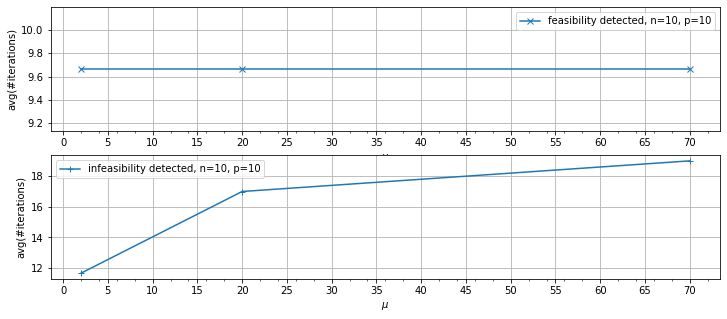

In [104]:
if __name__ == "__main__":
    plt.figure(figsize=(12, 5))
    ax = plt.subplot(2, 1, 1)
    plot_phase_I_feasibility_detection(n=10, p=10, n_dial=3, mus=[2 * x for x in range(1, 5, 5)] + [10 * x for x in range(2, 12, 5)], ax=ax)
    ax = plt.subplot(2, 1, 2)
    plot_phase_I_infeasibility_detection(n=10, p=10, n_dial=3, mus=[2 * x for x in range(1, 5, 5)] + [10 * x for x in range(2, 12, 5)], ax=ax)
    plt.show()